In [30]:
import random
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [31]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

test_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(CIFAR_MEAN, CIFAR_STD)])
DATA_DIR = "./data"

train_dataset = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=train_transform
)

# Отдельный вариант обучающей выборки без аугментации
train_eval_dataset = datasets.CIFAR10(
    root=DATA_DIR,
    train=True,
    download=False,
    transform=test_transform
)

test_dataset = datasets.CIFAR10(
    root=DATA_DIR,
    train=False,
    download=True,
    transform=test_transform
)

class_names = train_dataset.classes
print("Классы:", class_names)

Классы: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [32]:
print("Количество обучающих изображений:", len(train_dataset))
print("Количество тестовых изображений:", len(test_dataset))
print("Форма исходных обучающих изображений:", train_dataset.data.shape)
print("Форма меток обучающей выборки:", torch.tensor(train_dataset.targets).shape)
print("Форма исходных тестовых изображений:", test_dataset.data.shape)
print("Форма меток тестовой выборки:", torch.tensor(test_dataset.targets).shape)

Количество обучающих изображений: 50000
Количество тестовых изображений: 10000
Форма исходных обучающих изображений: (50000, 32, 32, 3)
Форма меток обучающей выборки: torch.Size([50000])
Форма исходных тестовых изображений: (10000, 32, 32, 3)
Форма меток тестовой выборки: torch.Size([10000])


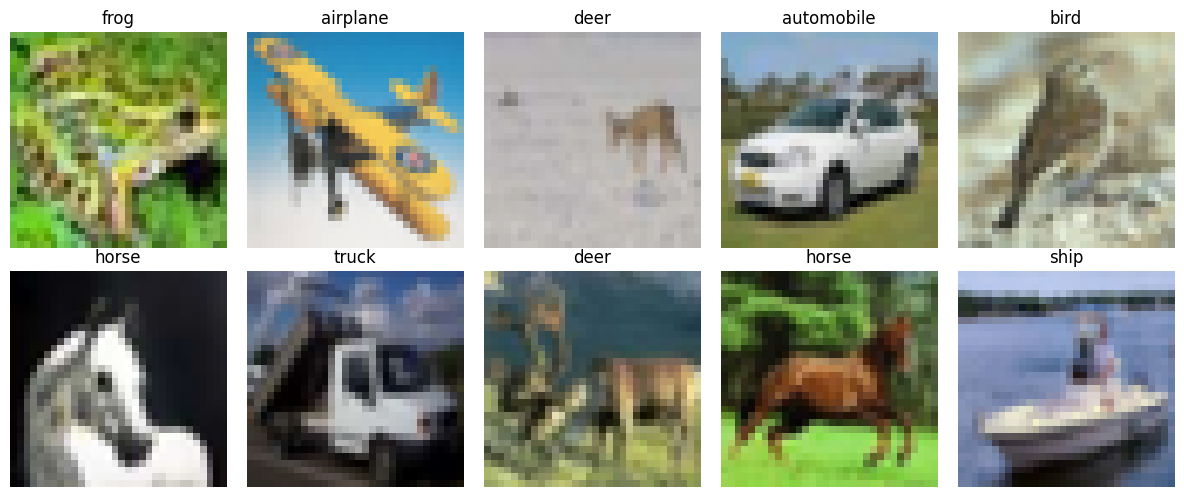

In [33]:
visual_loader = DataLoader(train_eval_dataset, batch_size=10, shuffle=True)
images, labels = next(iter(visual_loader))
mean_tensor = torch.tensor(CIFAR_MEAN).view(3, 1, 1)
std_tensor = torch.tensor(CIFAR_STD).view(3, 1, 1)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for index, ax in enumerate(axes.flat):
    image = images[index] * std_tensor + mean_tensor
    image = image.clamp(0, 1)
    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.set_title(class_names[labels[index].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [34]:
BATCH_SIZE = 128
NUM_WORKERS = 2

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
train_eval_loader = DataLoader(train_eval_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

In [35]:
class CIFAR10CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(
            # Первый блок: 3 x 32 x 32 -> 64 x 16 x 16
            nn.Conv2d(3, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(p=0.10),

            # Второй блок: 64 x 16 x 16 -> 128 x 8 x 8
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(p=0.15),

            # Третий блок: 128 x 8 x 8 -> 256 x 4 x 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.Conv2d(256, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2),
            nn.Dropout2d(p=0.20)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(256, 256), nn.ReLU(inplace=True), nn.Dropout(p=0.30), nn.Linear(256, num_classes))

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = self.classifier(x)
        return x


model = CIFAR10CNN(num_classes=10).to(device)


EPOCHS = 20
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=8, gamma=0.5)

In [36]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    total_loss = 0.0
    total_examples = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        total_examples += batch_size

    return total_loss / total_examples


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)
            predictions = outputs.argmax(dim=1)
            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (predictions == labels).sum().item()
            total_examples += batch_size

    average_loss = total_loss / total_examples
    accuracy = 100.0 * total_correct / total_examples
    classification_error = 100.0 - accuracy
    return average_loss, accuracy, classification_error

In [37]:
train_batch_losses = []
train_eval_losses = []
train_accuracies = []
train_errors = []

for epoch in range(EPOCHS):
    epoch_start_time = time.time()

    # Обучение на пакетах с аугментацией
    train_batch_loss = train_one_epoch(model, train_loader, criterion, optimizer, device)

    # Оценка на всей обучающей выборке без аугментации
    train_eval_loss, train_accuracy, train_error = evaluate(model, train_eval_loader, criterion, device)

    scheduler.step()
    epoch_time = time.time() - epoch_start_time
    train_batch_losses.append(train_batch_loss)
    train_eval_losses.append(train_eval_loss)
    train_accuracies.append(train_accuracy)
    train_errors.append(train_error)


    print(
        f"Эпоха [{epoch + 1:02d}/{EPOCHS}] | "
        f"Loss: {train_batch_loss:.4f} | "
        f"Train accuracy: {train_accuracy:.2f}% | "
        f"Ошибка классификации: {train_error:.2f}% | "
        f"Время: {epoch_time:.2f} сек"
    )

Эпоха [01/20] | Loss: 1.5449 | Train accuracy: 58.51% | Ошибка классификации: 41.49% | Время: 31.37 сек
Эпоха [02/20] | Loss: 1.1690 | Train accuracy: 64.15% | Ошибка классификации: 35.85% | Время: 31.36 сек
Эпоха [03/20] | Loss: 1.0090 | Train accuracy: 68.97% | Ошибка классификации: 31.03% | Время: 30.71 сек
Эпоха [04/20] | Loss: 0.8883 | Train accuracy: 72.32% | Ошибка классификации: 27.68% | Время: 30.59 сек
Эпоха [05/20] | Loss: 0.7917 | Train accuracy: 77.21% | Ошибка классификации: 22.79% | Время: 30.94 сек
Эпоха [06/20] | Loss: 0.7300 | Train accuracy: 78.76% | Ошибка классификации: 21.24% | Время: 30.26 сек
Эпоха [07/20] | Loss: 0.6702 | Train accuracy: 82.30% | Ошибка классификации: 17.70% | Время: 30.62 сек
Эпоха [08/20] | Loss: 0.6204 | Train accuracy: 83.37% | Ошибка классификации: 16.63% | Время: 31.25 сек
Эпоха [09/20] | Loss: 0.5351 | Train accuracy: 86.27% | Ошибка классификации: 13.73% | Время: 30.02 сек
Эпоха [10/20] | Loss: 0.5051 | Train accuracy: 85.83% | Ошибка к

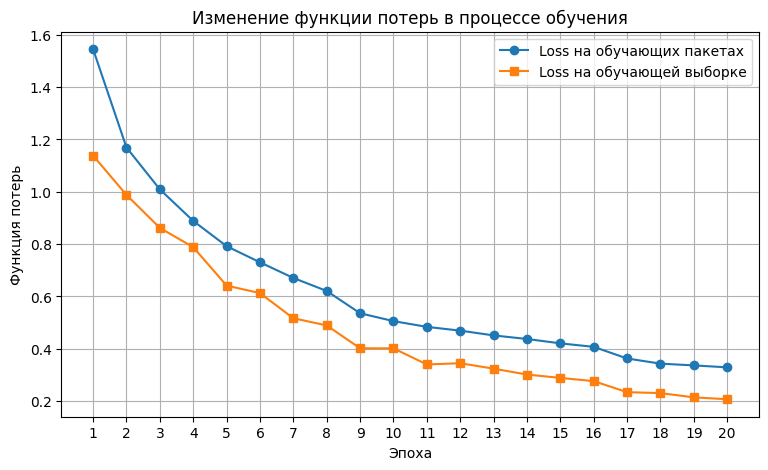

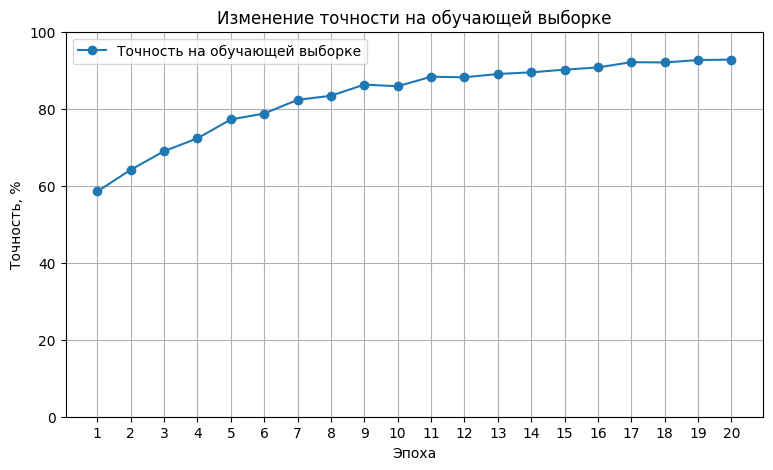

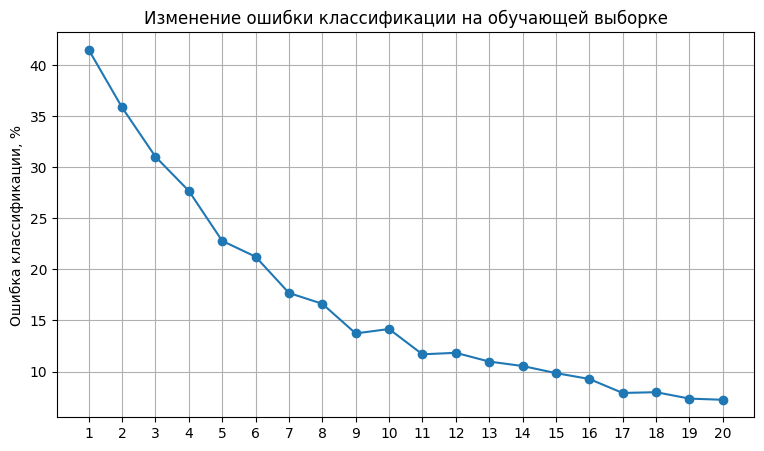

In [38]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(9, 5))
plt.plot(epochs_range, train_batch_losses, marker="o", label="Loss на обучающих пакетах")
plt.plot(epochs_range, train_eval_losses, marker="s", label="Loss на обучающей выборке")
plt.xlabel("Эпоха")
plt.ylabel("Функция потерь")
plt.title("Изменение функции потерь в процессе обучения")
plt.xticks(list(epochs_range))
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(epochs_range, train_accuracies, marker="o", label="Точность на обучающей выборке")
plt.xlabel("Эпоха")
plt.ylabel("Точность, %")
plt.title("Изменение точности на обучающей выборке")
plt.xticks(list(epochs_range))
plt.ylim(0, 100)
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(epochs_range, train_errors, marker="o")
plt.ylabel("Ошибка классификации, %")
plt.title("Изменение ошибки классификации на обучающей выборке")
plt.xticks(list(epochs_range))
plt.grid(True)
plt.show()

In [39]:
_, test_accuracy, test_error = evaluate(model, test_loader, criterion, device)

print(f"Точность классификации: {test_accuracy:.2f}%")
print(f"Ошибка классификации: {test_error:.2f}%")

Точность классификации: 89.01%
Ошибка классификации: 10.99%
